In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

In [8]:
def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

In [9]:
filenames = glob.glob("../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos*00000.root")
print(filenames)

['../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.100000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.400000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.700000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.500000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.300000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.200000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.800000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.000000.root']


In [10]:
ZScanData = {}
for f in filenames:
    key = f.split("Zpos")[1].split("00000")[0]
    print(key)
    ZScanData[key] = uproot.open(f)["pulse"].arrays()

50.1
50.6
50.4
50.7
50.5
50.3
50.2
50.8
50.


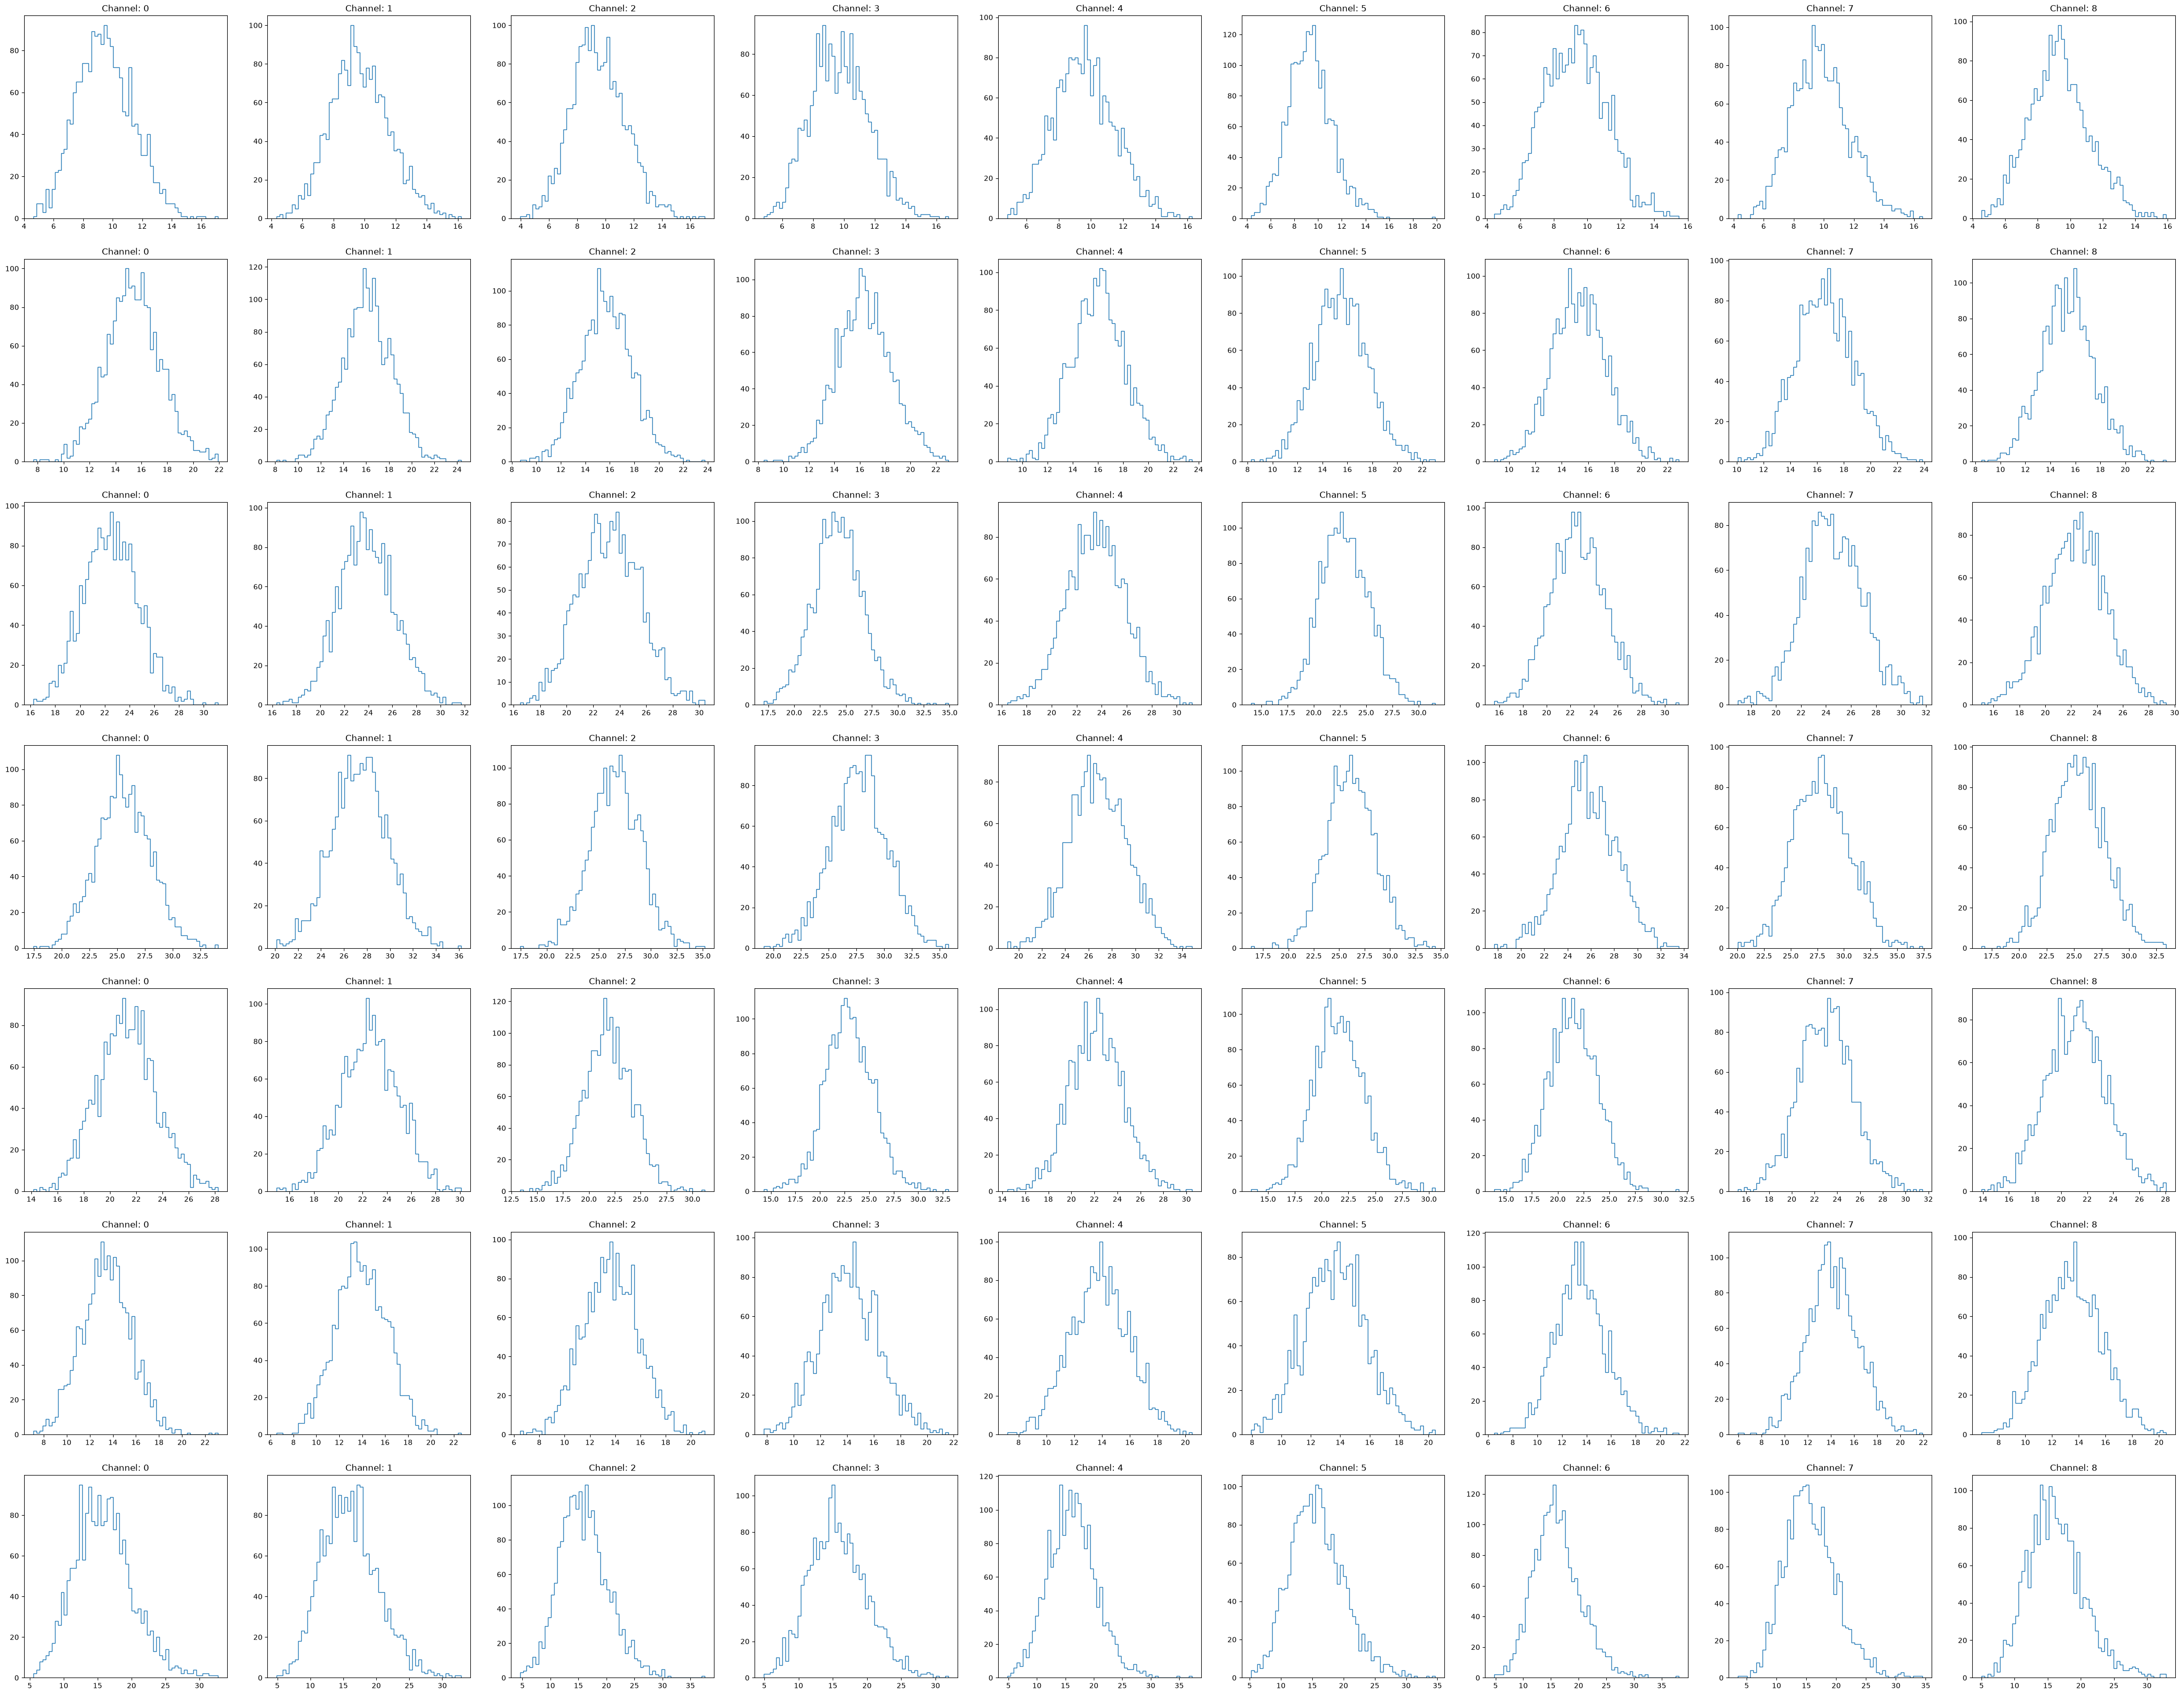

In [11]:
# Draw amplitudes
cols = len(ZScanData)
rows = 7
size = 6

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

amplitudes_mean = []
amplitudes_std = []

bins = 60

for i, key in enumerate(ZScanData.keys()):
    for j in range(7):
        ax[j][i].hist(ZScanData[key]["amp"][:, j], bins = bins, histtype = "step")
        ax[j][i].set_title(f"Channel: {i}")



/tmp/ipykernel_674815/2159317131.py:2: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-1 * (x - mean)**2 / 2*(std))
/tmp/ipykernel_674815/2159317131.py:2: RuntimeWarning: overflow encountered in multiply
  return A * np.exp(-1 * (x - mean)**2 / 2*(std))


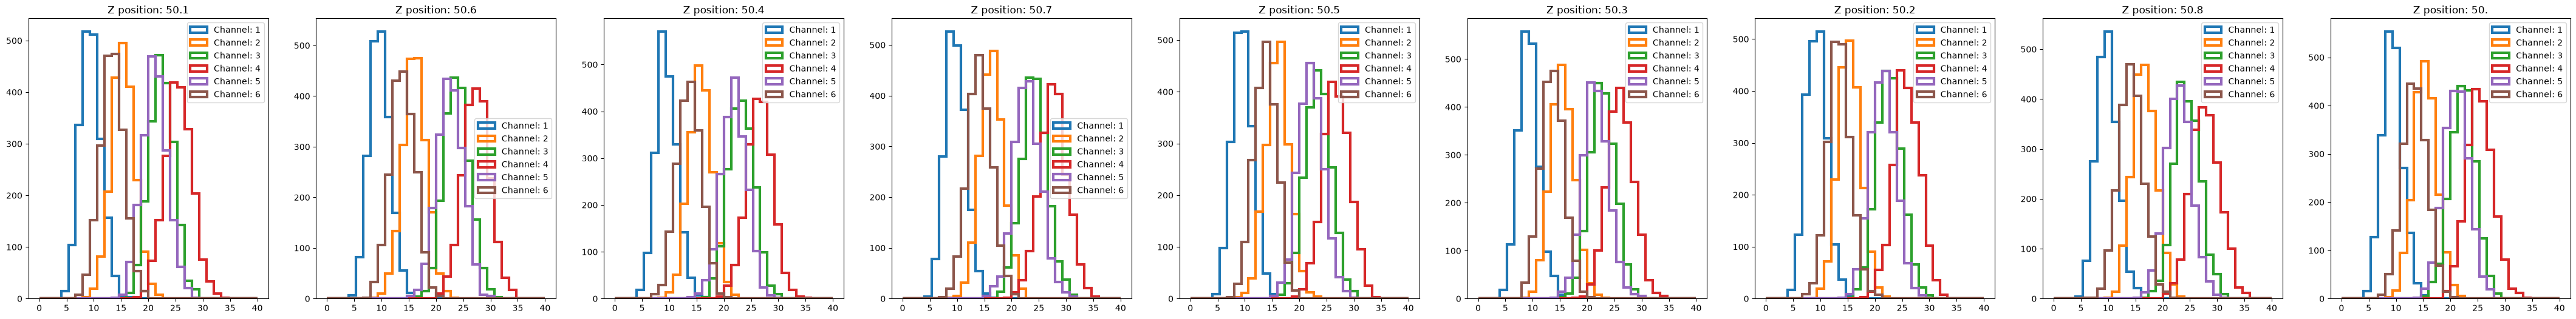

In [55]:
# Draw amplitudes
cols = len(ZScanData)
rows = 1
size = 6

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

amplitudes_mean = []
amplitudes_std = []

bins = 30
n_sigma = 2

plotting_range = (0, 40)

for i, key in enumerate(ZScanData.keys()):
    # if i < 4: continue
    channel_amplitude_mean = []
    channel_amplitude_std = []
    
    for j in range(6):
        y, x, polygon = ax[i].hist(ZScanData[key]["amp"][:, j], bins = bins, histtype = "step", label = f"Channel: {j+1}", linewidth = 3, range = plotting_range)
        # print(len(y), len(x))
        params = curve_fit(gaus, x[0:len(y)], y, p0=(max(y), np.mean(ZScanData[key]["amp"][:, j]), np.std(ZScanData[key]["amp"][:, j])))

        mean = params[0][1]
        std = params[0][2]

        channel_amplitude_mean.append(mean)
        channel_amplitude_std.append(std)

        fit_x_range = (x[0:bins]>mean-n_sigma*std)&(x[0:bins]<mean+n_sigma*std)
        y_axis = [gaus(x, params[0][0], params[0][1], params[0][2]) for x in x[0:bins][fit_x_range]]

    amplitudes_mean.append(channel_amplitude_mean)
    amplitudes_std.append(channel_amplitude_std)
    
    ax[i].set_title(f"Z position: {key}")
    ax[i].legend()
plt.show()

x_axis = np.array([float(i) for i in ZScanData.keys()])

order = np.argsort(x_axis)

x_axis = x_axis[order]
amplitudes_mean = np.array(amplitudes_mean)[order]
amplitudes_std = np.array(amplitudes_std)[order]


[50.  50.1 50.2 50.3 50.4 50.5 50.6 50.7 50.8]
[8.54264578 8.68640677 8.53069795 8.52062278 8.66620102 8.81271083
 8.92066836 8.9240361  9.00259323]
[14.66987303 14.68892216 14.59683352 14.72360415 14.99867871 15.37521813
 15.40281755 15.65444855 15.82686593]
[21.70401475 21.78013305 21.87776197 22.14165291 22.49175332 22.80873124
 23.06358814 23.51231309 23.77770516]
[24.66214683 24.87569637 25.11001659 25.377128   25.90431858 26.09246039
 26.67474446 27.03120617 27.12490455]
[20.43766697 20.52276212 20.76175928 20.82205435 21.18704667 21.4237735
 21.92779908 22.1967437  22.26879446]
[12.76016491 12.73793549 12.74180447 12.96519643 12.96348178 13.15934809
 13.21488198 13.40575406 13.42541527]


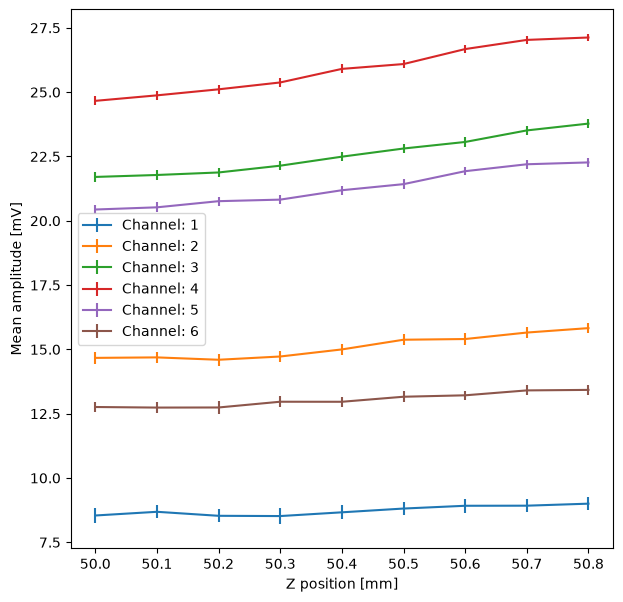

In [57]:
cols = 1
rows = 1
size = 7

print(x_axis)

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

for i in range(6):
    print(amplitudes_mean[:, i])
    ax.errorbar(x = x_axis, y = amplitudes_mean[:, i], yerr = amplitudes_std[:, i], label = f"Channel: {i+1}")
    ax.set_xlabel("Z position [mm]")
    ax.set_ylabel("Mean amplitude [mV]")
plt.legend()